# 03 · Suy luận (inference) và gọi API

Nạp mô hình đã lưu, dự đoán cho một hồ sơ, và gọi REST API giống cách giao diện Streamlit sử dụng.

In [1]:
from pathlib import Path
import sys
ROOT = Path.cwd()
if not (ROOT / "app").is_dir():
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
pd.set_option("display.max_columns", None)
from app.main import load_artifact, app
artifact = load_artifact()
artifact['metadata']['model_version'], artifact['metadata']['metrics']

('1.2.0', {'mae': 0.276097, 'rmse': 0.376241, 'r2': 0.91837})

In [2]:
profile = dict(Age=21, Gender='Female', Country='India', Academic_Level='Undergraduate', Most_Used_Platform='Instagram', Purpose_Of_Use='Education', Avg_Daily_Usage_Hours=4.0, Daily_Unlocks=120, Study_Hours=4.0, Physical_Activity_Hours=1.0, Sleep_Hours_Per_Night=7.0, Stress_Level='Medium')
float(artifact['model'].predict(pd.DataFrame([profile]))[0])

6.987499999999994

## What-if: thay đổi giờ dùng mạng xã hội

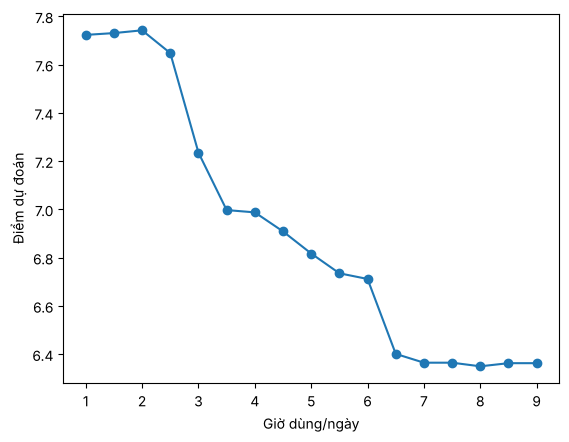

In [3]:
grid = np.arange(1, 9.01, 0.5)
rows = pd.DataFrame([{**profile, 'Avg_Daily_Usage_Hours': h} for h in grid])
plt.plot(grid, artifact['model'].predict(rows), 'o-'); plt.xlabel('Giờ dùng/ngày'); plt.ylabel('Điểm dự đoán'); plt.show()

## Gọi REST API (TestClient, không cần chạy uvicorn)

In [4]:
from fastapi.testclient import TestClient
payload = {'age': 21, 'gender': 'Female', 'country': 'Vietnam', 'academic_level': 'Undergraduate', 'most_used_platform': 'Instagram', 'purpose_of_use': 'Education', 'avg_daily_usage_hours': 12.0, 'daily_unlocks': 120, 'study_hours': 4.0, 'physical_activity_hours': 1.0, 'sleep_hours_per_night': 7.0, 'stress_level': 'Medium'}
with TestClient(app) as client:
    print(client.get('/health').json())
    response = client.post('/predict', json=payload)
    print(response.status_code, json.dumps(response.json(), ensure_ascii=False, indent=2))

2026-11-21 16:17:55,703 INFO app Loaded model artifact from /home/claude/merge/ML_SK/models/mental_health_model.joblib


2026-11-21 16:17:55,709 INFO app GET /health -> 200 in 2.0 ms


2026-11-21 16:17:55,767 INFO app Prediction score=6.33 model_version=1.2.0 selected_model=random_forest


2026-11-21 16:17:55,769 INFO app POST /predict -> 200 in 57.3 ms


{'status': 'ok', 'model_loaded': True, 'model_version': '1.2.0'}
200 {
  "mental_health_score": 6.33,
  "score_scale": "0-10",
  "model_version": "1.2.0",
  "warnings": [
    "Avg_Daily_Usage_Hours=12 nằm ngoài khoảng dữ liệu huấn luyện [1, 8.8]; mô hình không ngoại suy nên kết quả không đáng tin.",
    "Country='Vietnam' chỉ có 5 dòng trong dữ liệu huấn luyện; độ tin cậy thấp."
  ]
}


API vẫn trả điểm nhưng kèm cảnh báo, vì 12 giờ/ngày nằm ngoài dữ liệu huấn luyện (1-8.8 giờ) và Vietnam chỉ có 5 dòng.